# Regresión Logística (clasificación binaria)

**Programa Especializado en Inteligencia Artificial** · C-DAC Noida · ITEC · India 2026  
Resuelto paso a paso — PhD (c) Luis Correa

## Predecir si una persona compra seguro según su edad
Problema de **clasificación binaria**: solo hay dos resultados (compra / no compra).

In [1]:
import pandas as pd
from matplotlib import pyplot as plt

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/luiscorrea4041-ux/practicas-ia-cdac/main/data/insurance_data.csv')
df.head()

,age,bought_insurance
0,22,0
1,25,0
2,47,1
3,52,0
4,46,1


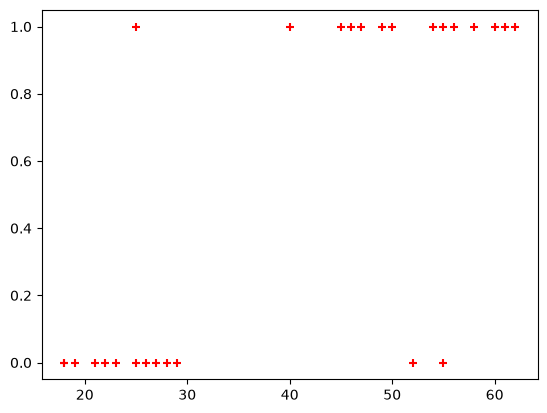

In [3]:
plt.scatter(df.age, df.bought_insurance, marker='+', color='red')
plt.show()

In [4]:
from sklearn.model_selection import train_test_split

X = df[['age']]
y = df.bought_insurance

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=10)

In [5]:
X_test

,age
7,60
5,56
18,19
21,26
11,28
1,25


In [6]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()

model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [7]:
y_predicted = model.predict(X_test)
y_predicted

array([1, 1, 0, 0, 0, 0])

In [8]:
model.predict_proba(X_test)

array([[0.07149837, 0.92850163],
       [0.10786034, 0.89213966],
       [0.88695424, 0.11304576],
       [0.78083769, 0.21916231],
       [0.73981335, 0.26018665],
       [0.79952571, 0.20047429]])

In [9]:
model.score(X_test, y_test)

1.0

`model.coef_` es la **m** y `model.intercept_` es la **b** de  y = m·x + b.

In [10]:
model.coef_

array([[0.112778]])

In [11]:
model.intercept_

array([-4.20278276])

Definimos la **sigmoide** y hacemos la cuenta a mano:

In [12]:
import math
def sigmoid(z):
    return 1 / (1 + math.exp(-z))

In [13]:
def prediction_function(age):
    z = 0.112778 * age - 4.20278276
    y = sigmoid(z)
    return y

In [14]:
age = 54
prediction_function(age)

0.8684392873694103

In [15]:
age = 22
prediction_function(age)

0.15165659899611397

## Ejercicio práctico: retención de empleados (HR)
Analizar qué variables influyen en que un empleado se quede o se vaya, graficar el impacto del salario y del departamento, y construir un modelo de regresión logística midiendo su precisión.

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

# PASO 1: cargar y explorar
df = pd.read_csv('https://raw.githubusercontent.com/luiscorrea4041-ux/practicas-ia-cdac/main/data/HR_comma_sep.csv')
print('Total de empleados:', len(df))
print('Se quedaron (0) vs se fueron (1):')
print(df['left'].value_counts())

Total de empleados: 14999
Se quedaron (0) vs se fueron (1):
left
0    11428
1     3571
Name: count, dtype: int64


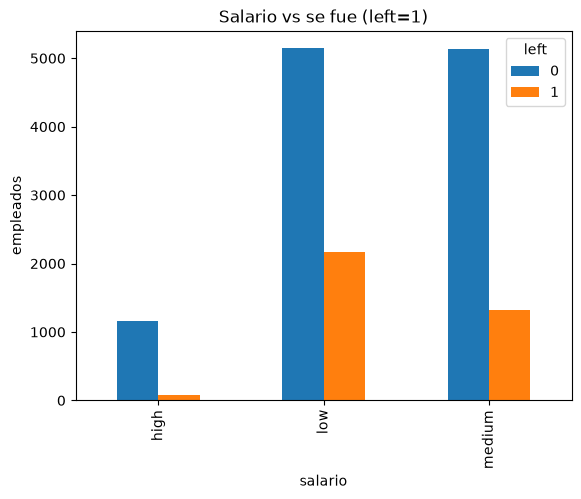

In [17]:
# PASO 2: salario vs se fue
pd.crosstab(df.salary, df.left).plot(kind='bar')
plt.title('Salario vs se fue (left=1)'); plt.xlabel('salario'); plt.ylabel('empleados')
plt.show()

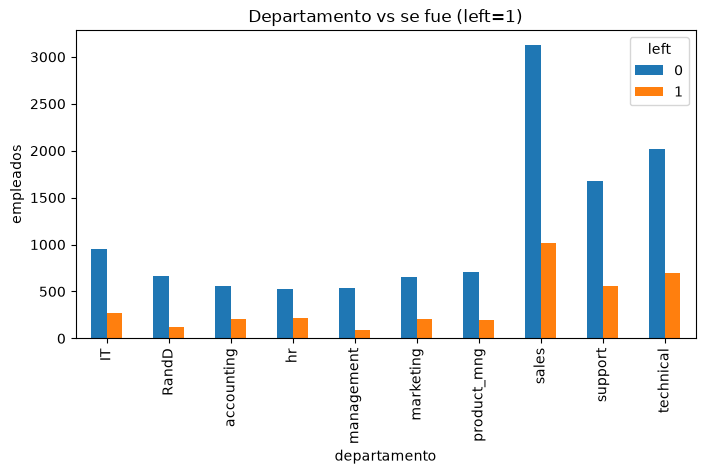

In [18]:
# PASO 3: departamento vs se fue
pd.crosstab(df.Department, df.left).plot(kind='bar', figsize=(8,4))
plt.title('Departamento vs se fue (left=1)'); plt.xlabel('departamento'); plt.ylabel('empleados')
plt.show()

In [19]:
# PASO 4: elegir variables y convertir el salario a números (dummy)
sub = df[['satisfaction_level','average_montly_hours','promotion_last_5years','salary','left']]
dummies = pd.get_dummies(sub['salary'], prefix='salary')
final = pd.concat([sub.drop('salary', axis='columns'), dummies], axis='columns')
X = final.drop('left', axis='columns')
y = final['left']
print('Columnas usadas:', list(X.columns))

Columnas usadas: ['satisfaction_level', 'average_montly_hours', 'promotion_last_5years', 'salary_high', 'salary_low', 'salary_medium']


In [20]:
# PASO 5: entrenar y medir la precisión
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, random_state=10)
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
print('PRECISIÓN del modelo (score):', round(model.score(X_test, y_test), 4))

PRECISIÓN del modelo (score): 0.7707
